# An N-gram language model

A trigram model (`N = 3`) predicts the next word from the previous two. Training means counting which words follow each context. We'll keep repeated observations in a list, so picking a random item gives frequent words a higher chance.

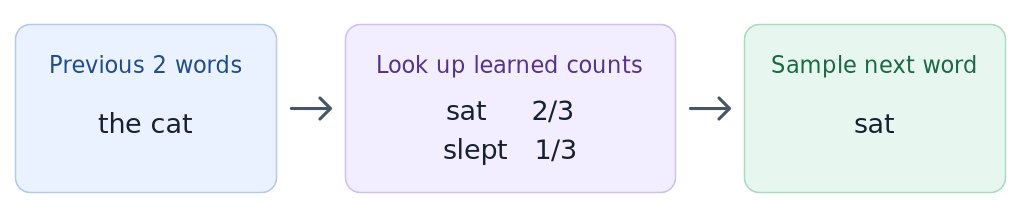

In [23]:
# 1. Dataset: one string per sentence
dataset = [
    "the cat sat on the mat sat on the cat",
    "the cat sat by the window",
    "the cat slept on the sofa",
    "the dog sat by the door",
    "the dog slept on the mat",
    "the bird sat by the window",
]

N = 3

## Train

Slide a window of `N` words over each sentence. Use the first `N - 1` words as a dictionary key (a tuple), then add the last word to its list. The `<start>` and `<end>` markers let the model learn how sentences begin and end.

In [25]:
model = {}

for sentence in dataset:
    words = ["<start>"] * (N - 1) + sentence.lower().split() + ["<end>"]
    print(words)
    for i in range(len(words) - N + 1):
        context = tuple(words[i : i + N - 1])
        next_word = words[i + N - 1]

        if context not in model:
            model[context] = []
        model[context].append(next_word)
    
    print(model)

['<start>', '<start>', 'the', 'cat', 'sat', 'on', 'the', 'mat', 'sat', 'on', 'the', 'cat', '<end>']
{('<start>', '<start>'): ['the'], ('<start>', 'the'): ['cat'], ('the', 'cat'): ['sat', '<end>'], ('cat', 'sat'): ['on'], ('sat', 'on'): ['the', 'the'], ('on', 'the'): ['mat', 'cat'], ('the', 'mat'): ['sat'], ('mat', 'sat'): ['on']}
['<start>', '<start>', 'the', 'cat', 'sat', 'by', 'the', 'window', '<end>']
{('<start>', '<start>'): ['the', 'the'], ('<start>', 'the'): ['cat', 'cat'], ('the', 'cat'): ['sat', '<end>', 'sat'], ('cat', 'sat'): ['on', 'by'], ('sat', 'on'): ['the', 'the'], ('on', 'the'): ['mat', 'cat'], ('the', 'mat'): ['sat'], ('mat', 'sat'): ['on'], ('sat', 'by'): ['the'], ('by', 'the'): ['window'], ('the', 'window'): ['<end>']}
['<start>', '<start>', 'the', 'cat', 'slept', 'on', 'the', 'sofa', '<end>']
{('<start>', '<start>'): ['the', 'the', 'the'], ('<start>', 'the'): ['cat', 'cat', 'cat'], ('the', 'cat'): ['sat', '<end>', 'sat', 'slept'], ('cat', 'sat'): ['on', 'by'], ('sat

## Predict the next word

For `the cat`, the model saw `sat` twice and `slept` once. The probability of `sat` is therefore 2 out of 3.

In [27]:
prefix = "the cat"
words = ["<start>"] * (N - 1) + prefix.lower().split()
context = tuple(words[len(words) - (N - 1) :])
choices = model.get(context, [])

print("Context:", context)
print("Observations:", choices)
for word in sorted(set(choices)):
    print(word, choices.count(word) / len(choices))

Context: ('the', 'cat')
Observations: ['sat', '<end>', 'sat', 'slept']
<end> 0.25
sat 0.5
slept 0.25


## Generate a sentence

Start with an empty sentence. Sample the next word, move the context window one word forward, and repeat until `<end>` or the word limit.

In [28]:
import random


def generate(max_words=20):
    context = ("<start>",) * (N - 1)
    print(context)
    sentence = []

    for _ in range(max_words):
        word = random.choice(model[context])
        if word == "<end>":
            break
        sentence.append(word)
        context = (context + (word,))[1:]

    return " ".join(sentence)


for _ in range(5):
    print(generate())

('<start>', '<start>')
the bird sat by the door
('<start>', '<start>')
the cat sat by the window
('<start>', '<start>')
the dog sat by the window
('<start>', '<start>')
the cat sat by the window
('<start>', '<start>')
the cat sat on the mat


Try `N = 2` or `N = 1` and run all cells again. What changes in the next-word probabilities and generated sentences?